In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from iris.config import PATHS
from iris.data.tiling import open_slide, thumbnail

df = pd.read_csv(PATHS.train_csv)
have = {p.stem for p in PATHS.images.glob("*.tiff")}
mine = df[df.image_id.isin(have)]
mine

,image_id,data_provider,isup_grade,gleason_score
264,06fe0864a99a2e0cd32cb141b7808912,radboud,3,4+3
1891,2fb49b4bb80d5c1f3b5b2fc44fa8a763,radboud,4,4+4
3048,4c7bdcaec94446929471c97fa0c8088b,karolinska,1,3+3
3184,4fc9b7a068848becc2f8cbf978bb393c,karolinska,0,0+0
4399,6cfaf603c5b30bacd9363448ca9fe57f,karolinska,2,3+4
5441,8634ef0b80d1353887839c0a4a36e074,radboud,0,negative
5904,913a2707c4014d58fc950f0bcad251e2,karolinska,4,4+4
6201,980231066d0cb7d43fc3993e6fb2f619,radboud,5,5+5
6259,991d3df8e3ce4a9f4b0edc588070b0e7,radboud,1,3+3
7087,ac46e4ee5b43c383cbea6287ea67c3bb,karolinska,0,0+0


In [8]:
row = mine[mine.isup_grade == 2].iloc[0]
slide = open_slide(PATHS.images / f"{row.image_id}.tiff")
print(row.data_provider, "| ISUP", row.isup_grade, "| Gleason", row.gleason_score)
print("levels:", slide.level_dimensions)

karolinska | ISUP 2 | Gleason 3+4
levels: ((16384, 22016), (4096, 5504), (1024, 1376))


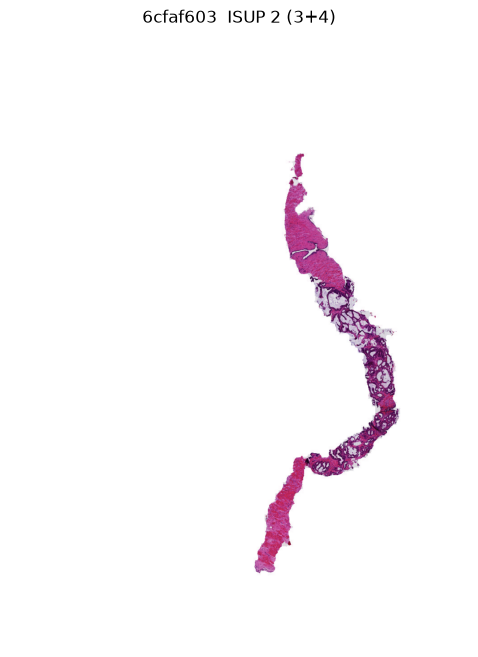

In [9]:
img = thumbnail(slide, 2)          # level 2 = the smallest zoom level
plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.title(f"{row.image_id[:8]}  ISUP {row.isup_grade} ({row.gleason_score})")
plt.axis("off");

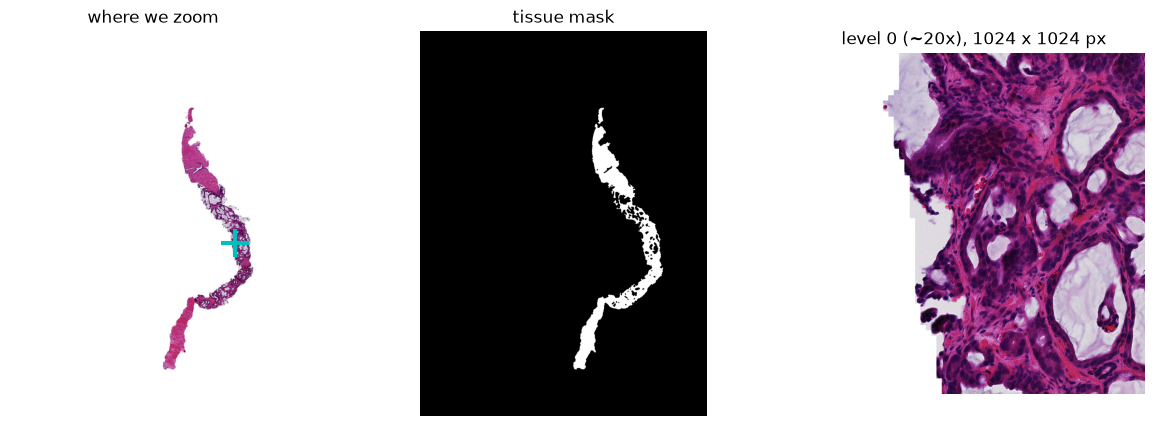

In [12]:
import numpy as np
from iris.data.tissue import tissue_mask

mask = tissue_mask(img)                 # True where there is tissue
ys, xs = np.nonzero(mask)
i = len(ys) // 2                        # a point in the middle of the tissue
down = slide.level_downsamples[2]       # level-2 pixel -> level-0 pixel
x0, y0 = int(xs[i] * down), int(ys[i] * down)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img); ax[0].plot(xs[i], ys[i], "c+", ms=20, mew=3); ax[0].set_title("where we zoom")
ax[1].imshow(mask, cmap="gray"); ax[1].set_title("tissue mask")
ax[2].imshow(slide.read_region((x0 - 512, y0 - 512), 0, (1024, 1024)).convert("RGB"))
ax[2].set_title("level 0 (~20x), 1024 x 1024 px")
for a in ax: a.axis("off")


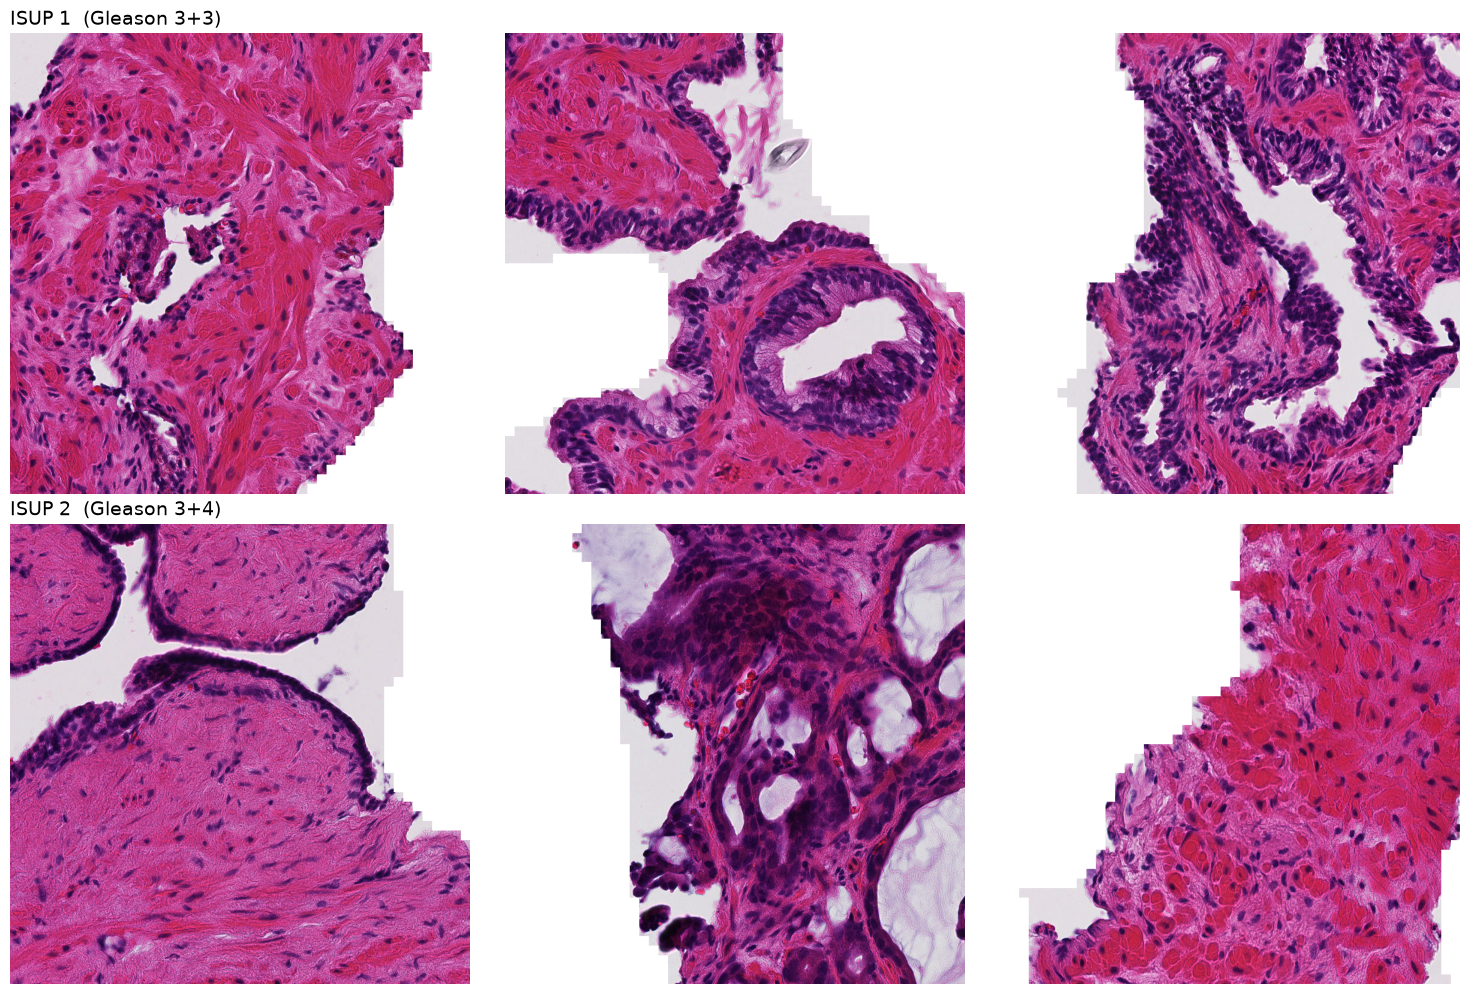

In [13]:
def zooms(row, n=3, size=768):
    """Open a slide and cut `n` full-resolution crops spread along its tissue."""
    s = open_slide(PATHS.images / f"{row.image_id}.tiff")
    small = thumbnail(s, 2)
    ys, xs = np.nonzero(tissue_mask(small))
    down = s.level_downsamples[2]
    crops = []
    for frac in np.linspace(0.2, 0.8, n):            # 20%, 50%, 80% along the tissue
        k = int(frac * len(ys))
        x0, y0 = int(xs[k] * down), int(ys[k] * down)
        crops.append(s.read_region((x0 - size // 2, y0 - size // 2), 0, (size, size)).convert("RGB"))
    return crops

# one GG1 and one GG2 slide from the SAME lab, so stain colour is comparable
lab = "karolinska"
gg1 = mine[(mine.isup_grade == 1) & (mine.data_provider == lab)].iloc[0]
gg2 = mine[(mine.isup_grade == 2) & (mine.data_provider == lab)].iloc[0]

fig, ax = plt.subplots(2, 3, figsize=(15, 10))
for r, row in enumerate([gg1, gg2]):
    for c, crop in enumerate(zooms(row)):
        ax[r, c].imshow(crop)
        ax[r, c].axis("off")
    ax[r, 0].set_title(f"ISUP {row.isup_grade}  (Gleason {row.gleason_score})", loc="left", fontsize=14)
plt.tight_layout()
